In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from collections import defaultdict
from copy import deepcopy

import pandas as pd
import numpy as np
from tqdm import tqdm, trange
import matplotlib.pyplot as plt

from IPython.display import clear_output

from recover.constants import DATA_DIR

luh = pd.read_parquet(DATA_DIR / 'esa_and_luh_timeseries/luh_timeseries.parquet').set_index('ID')
esa = pd.read_parquet(DATA_DIR / 'esa_and_luh_timeseries/esa_timeseries.parquet').set_index('ID')
# Join X and Y coords
esa = esa.join(luh[['x', 'y']].drop_duplicates(), how='inner')

esa['year'] = esa['year'].astype(int)
luh['year'] = luh['year'].astype(int)

In [3]:
from recover.dataset import RasterDataset
ds = RasterDataset(luh)
ds

Initialising raster dataset with bands ['pastr', 'primf', 'primn', 'range', 'secdf', 'secdn', 'urban', 'crops']
Finished building array with shape (130, 8, 301, 305)


In [4]:
diff = np.diff(ds.arr, axis=0)
changed = diff > 0.01

moved = changed.any(axis=1) 

In [5]:
T = len(ds.time_steps)
times = np.where(moved, np.arange(T - 1)[:, None, None], T)
first = times.min(axis=0)

y, x = np.unravel_index(np.argmin(first), (ds.H, ds.W))
t = first[y, x]
x, y, t

(np.int64(9), np.int64(0), np.int64(0))

In [17]:
(~np.isnan(ds.arr.mean(axis=0).mean(axis=0))).sum() / (ds.W * ds.H)

np.float64(0.28675998039322476)

In [50]:
luh['year'].unique(), esa['year'].unique()

(array([1515, 1540, 1565, 1590, 1615, 1640, 1665, 1690, 1715, 1740, 1765,
        1790, 1815, 1840, 1865, 1890, 1915, 1940, 1965, 1990, 1991, 1992,
        1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003,
        2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014,
        2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025,
        2026, 2027, 2028, 2029, 2030, 2031, 2032, 2033, 2034, 2035, 2036,
        2037, 2038, 2039, 2040, 2041, 2042, 2043, 2044, 2045, 2046, 2047,
        2048, 2049, 2050, 2051, 2052, 2053, 2054, 2055, 2056, 2057, 2058,
        2059, 2060, 2061, 2062, 2063, 2064, 2065, 2066, 2067, 2068, 2069,
        2070, 2071, 2072, 2073, 2074, 2075, 2076, 2077, 2078, 2079, 2080,
        2081, 2082, 2083, 2084, 2085, 2086, 2087, 2088, 2089, 2090, 2091,
        2092, 2093, 2094, 2095, 2096, 2097, 2098, 2099, 2100]),
 array([1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002,
        2003, 2004, 2005, 2006, 2007, 2008, 2009

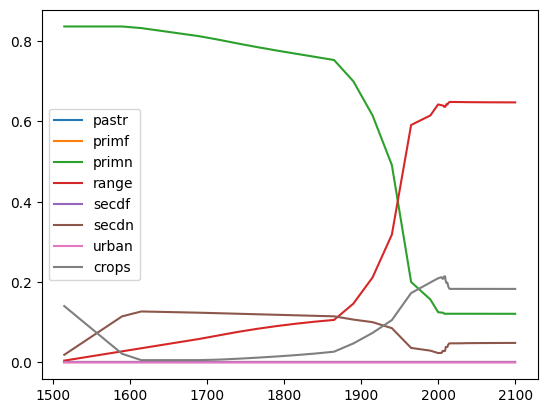

In [45]:
def plot_pixel_over_time(ds, x=9, y=0, b=1):
    # plt.plot(ds.time_steps[1:], np.diff(ds._arr, axis=0)[:, b, y, x])
    plt.plot(ds.time_steps, ds._arr[:, b, y, x])

for b in range(len(ds.bands)):
    plot_pixel_over_time(ds, b=b)
plt.legend(ds.bands)

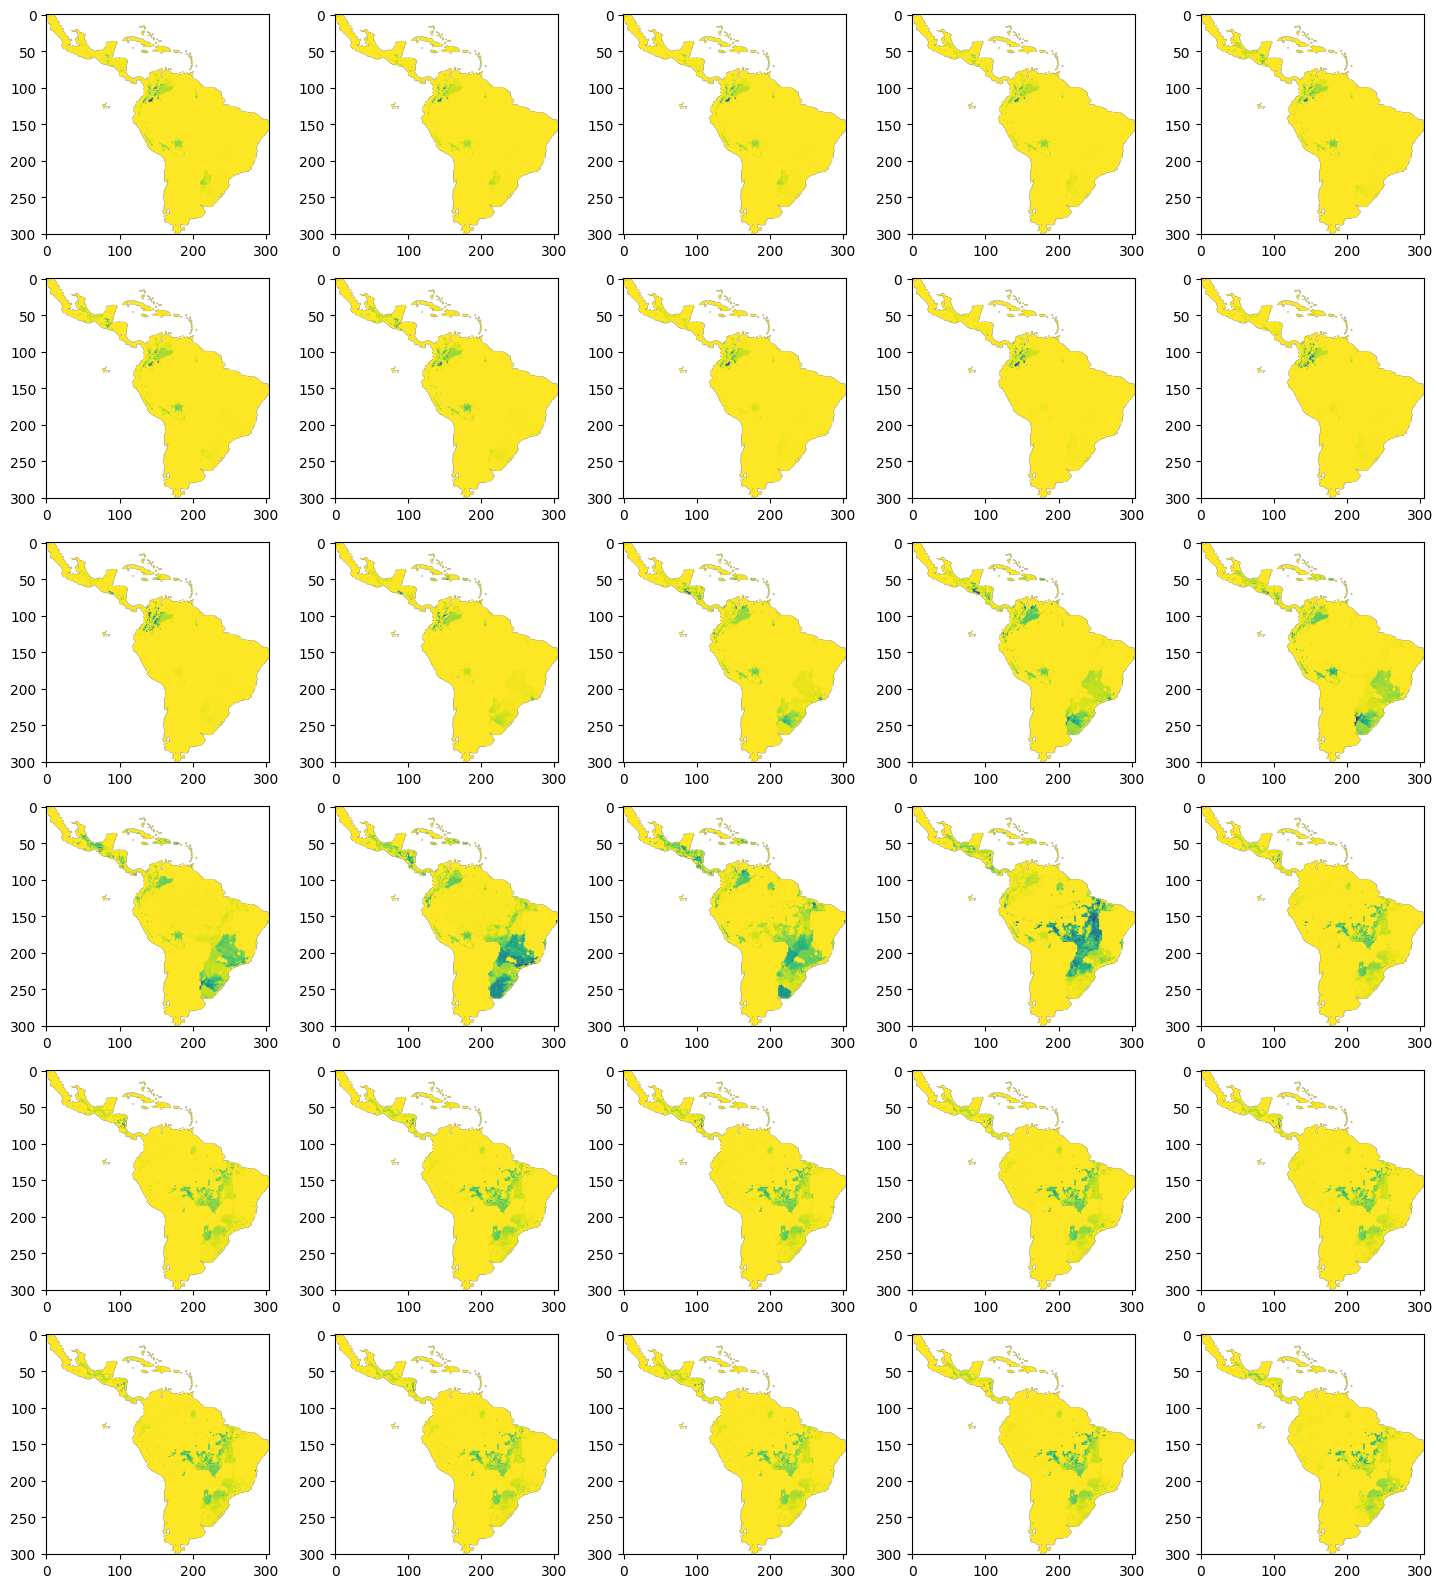

In [40]:
plt.figure(figsize=(18, 20))
for i in range(30):
    plt.subplot(6, 5, i+1)
    plt.imshow(np.diff(ds._arr, axis=0)[i, 1, :, :])
plt.show()

<Figure size 640x480 with 0 Axes>

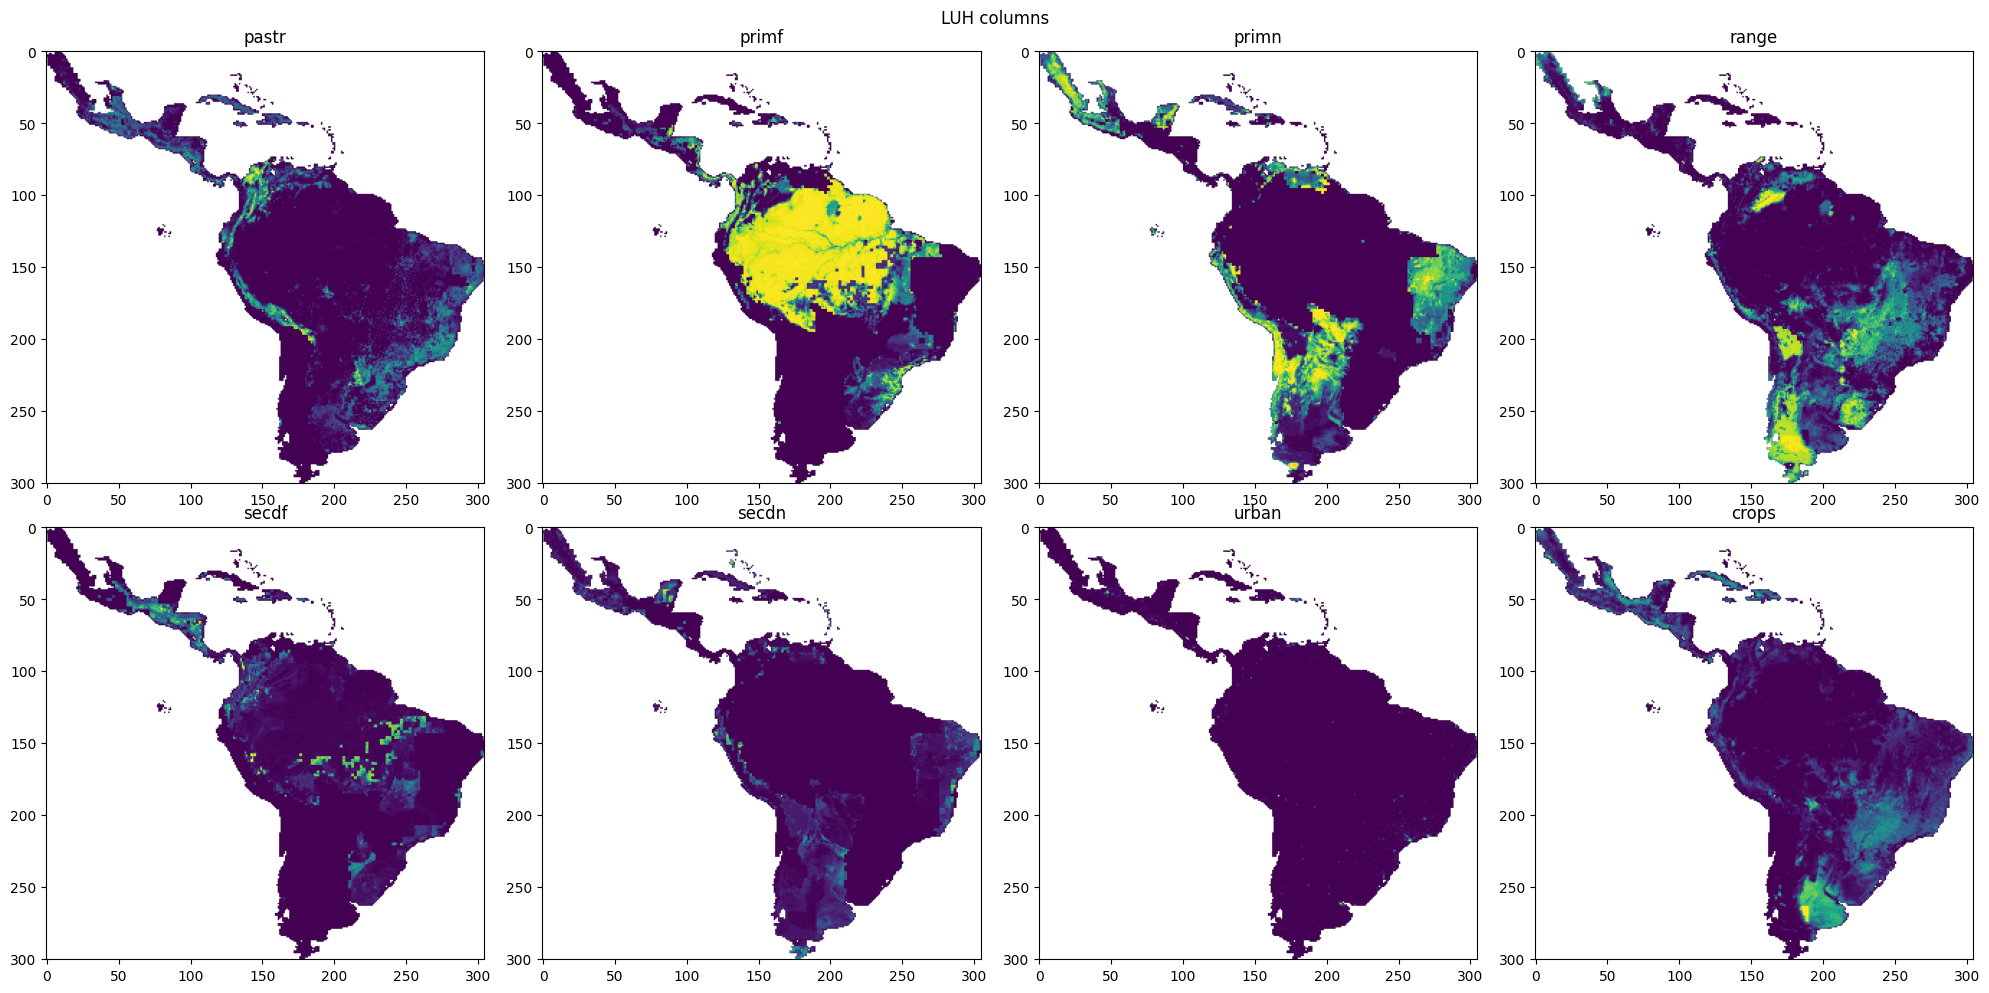

In [13]:
luh_cols = ['pastr', 'primf', 'primn', 'range', 'secdf', 'secdn', 'urban', 'crops',]
esa_cols = [c for c in df.columns if c.startswith('ESA')]
img = to_img(single_year, cols=luh_cols)
show_raster(img, channel_names=luh_cols)
f = plt.gcf()
f.suptitle('LUH columns')
f.tight_layout()

In [ ]:
t = 2022
RasterDataset()

<Figure size 640x480 with 0 Axes>

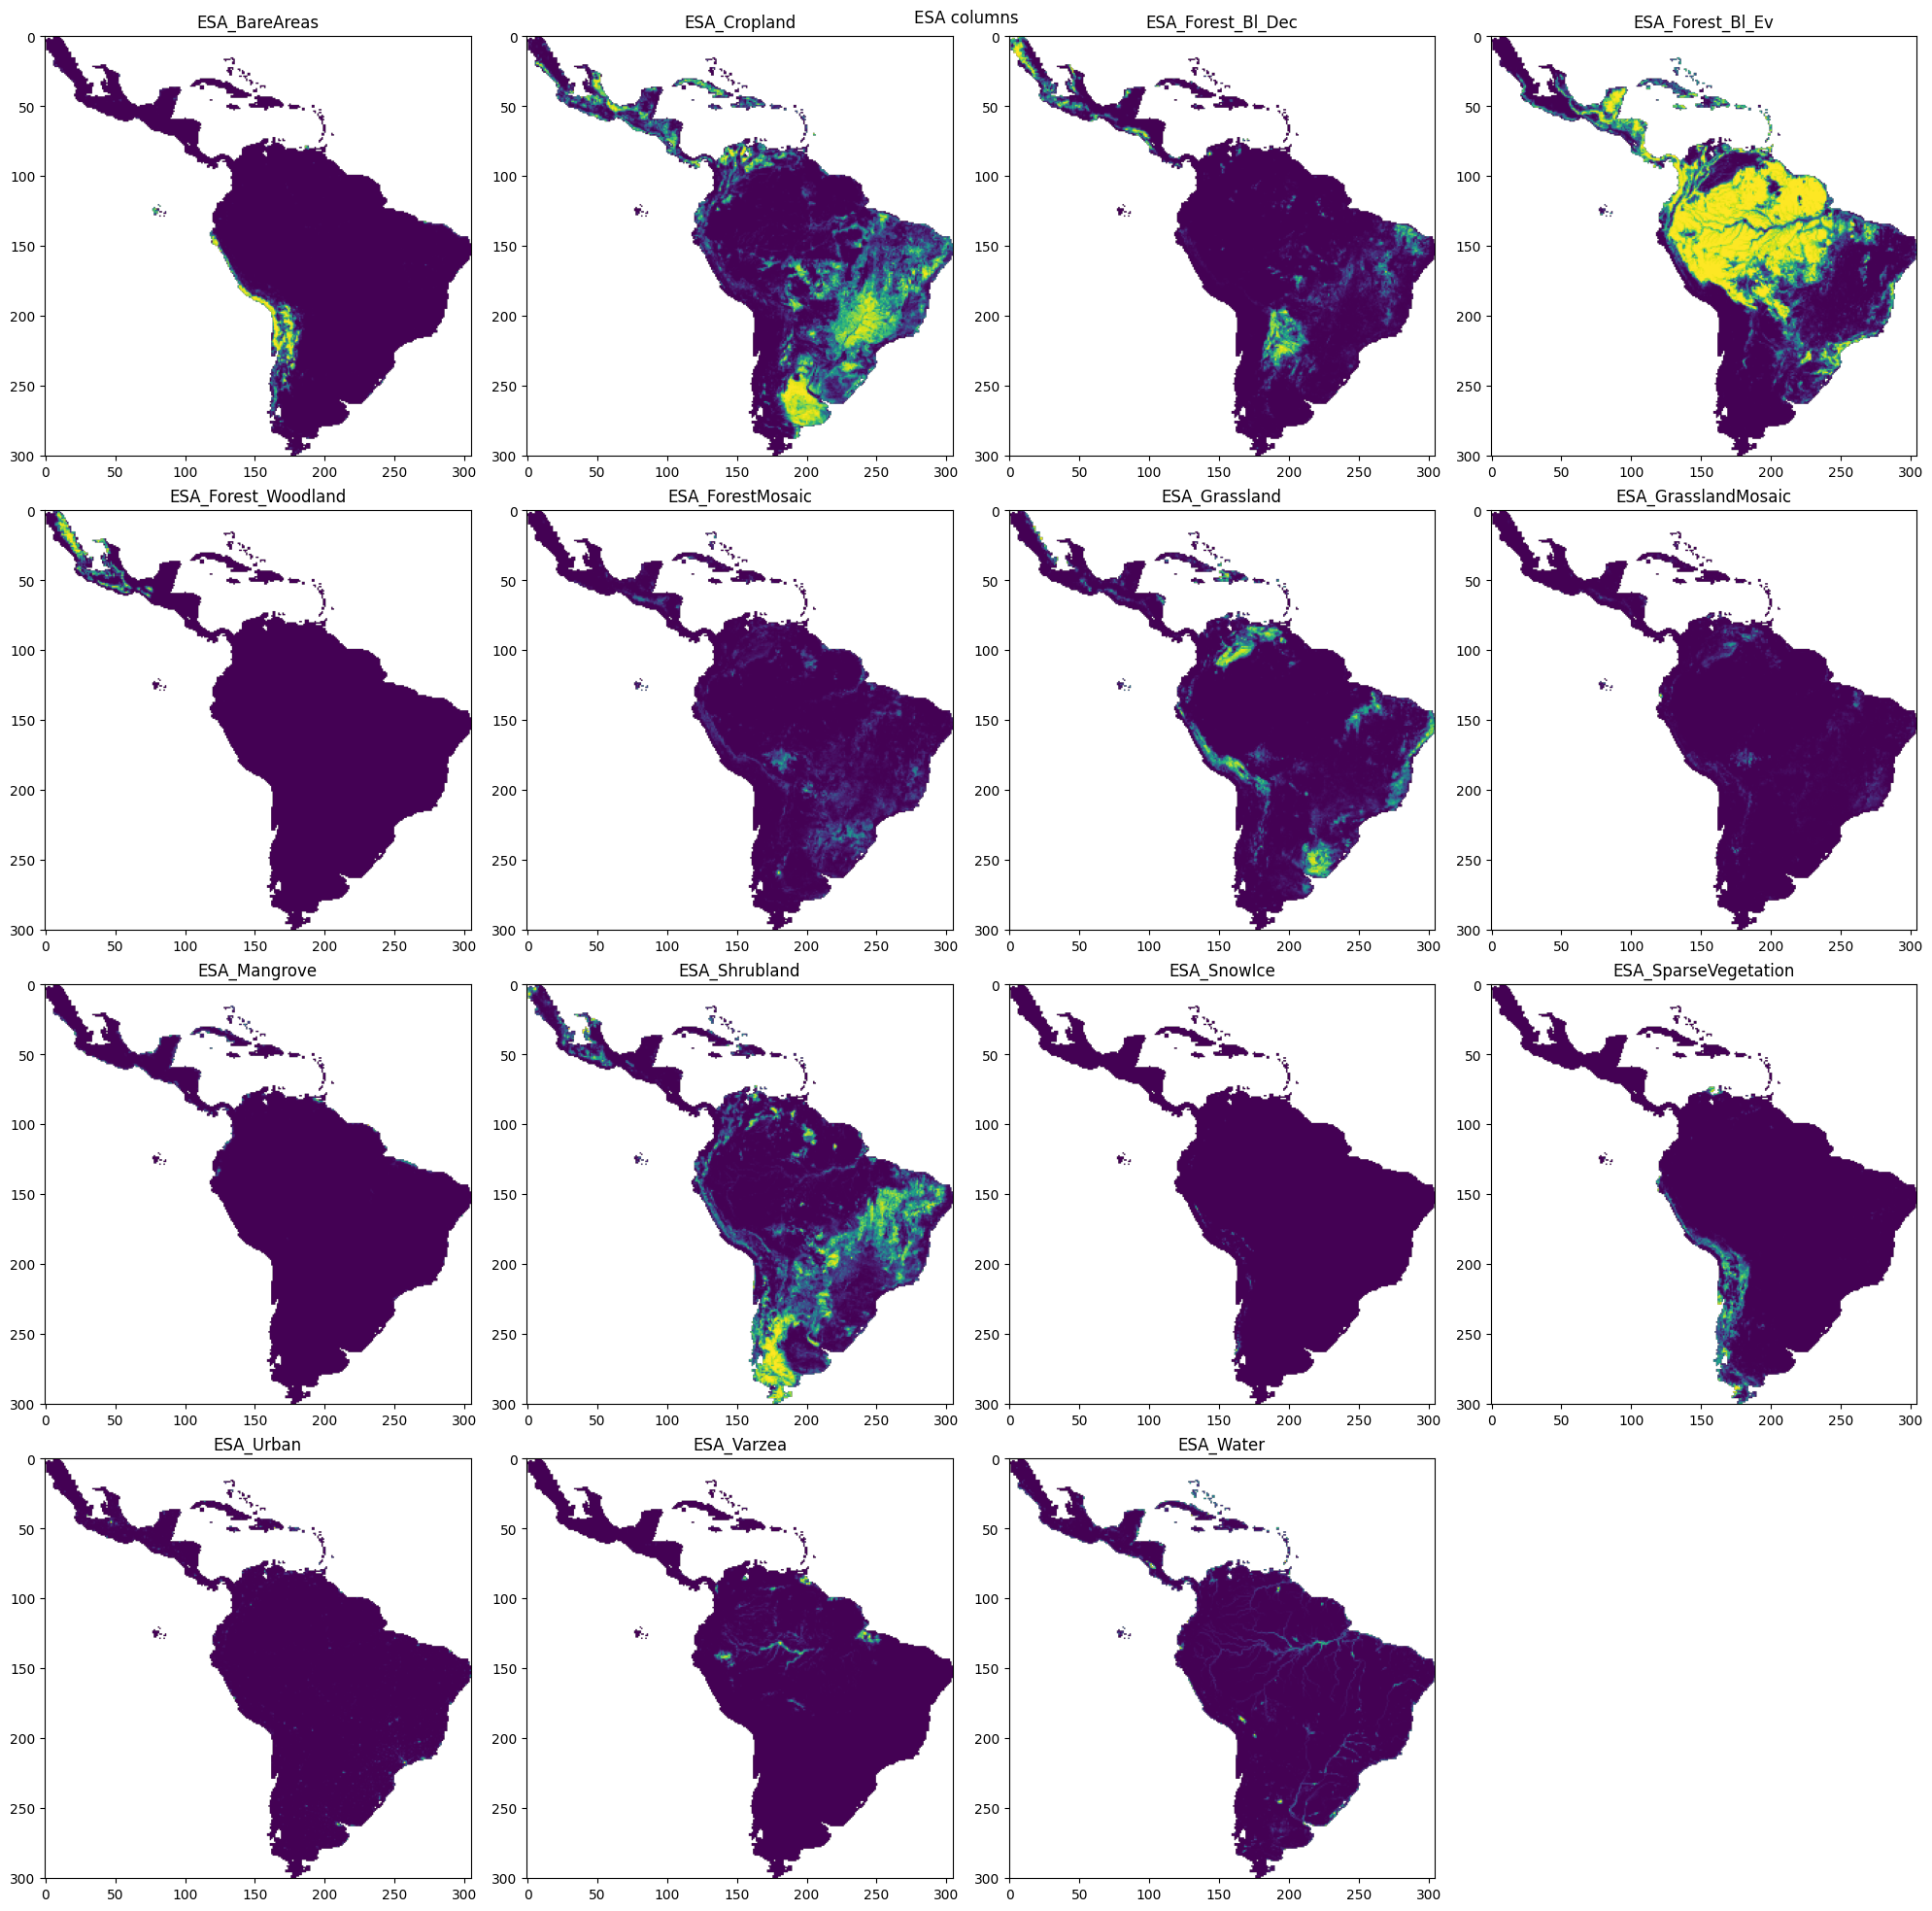

In [14]:
img = to_img(single_year, cols=esa_cols)
show_raster(img, channel_names=esa_cols)

f = plt.gcf()
f.suptitle('ESA columns')
f.tight_layout()

# Data loaders for torch

In [77]:
def temporal_split(df, train_start=2009, val_start=2001):
    train = df[df.year >= train_start].copy()
    val = df[(df.year >= val_start) & (df.year < train_start)].copy()
    test = df[df.year < val_start].copy()
    return train, val, test


def add_coord_features(df):
    df = df.copy()

    if {"x", "y"}.issubset(df.columns):
        lon = np.deg2rad(df["x"])
        lat = np.deg2rad(df["y"])

        df["lon_sin"] = np.sin(lon)
        # df["lon_cos"] = np.cos(lon)
        df["lat_sin"] = np.sin(lat)
        # df["lat_cos"] = np.cos(lat)

    return df


def fit_feature_stats(df, feature_cols):
    stats = {}

    for c in feature_cols:
        if c in {"x", "y"}:
            continue

        stats[c] = {
            "mean": df[c].mean(),
            "std": max(df[c].std(), 1e-8),
        }

    return stats


def transform_features(df, feature_cols, stats):
    X = df[feature_cols].copy()

    for c in feature_cols:
        if c in stats:
            X[c] = (X[c] - stats[c]["mean"]) / stats[c]["std"]

    return X.astype(np.float32)


class RasterDataset(Dataset):
    def __init__(
        self,
        df,
        feature_cols,
        target_cols,
        stats=None,
    ):
        df = add_coord_features(df)

        feature_cols = list(feature_cols)

        if "x" in feature_cols:
            feature_cols.remove("x")
            feature_cols.extend(["lon_sin"])

        if "y" in feature_cols:
            feature_cols.remove("y")
            feature_cols.extend(["lat_sin"])

        self.feature_cols = feature_cols
        self.target_cols = target_cols

        if stats is None:
            stats = fit_feature_stats(df, feature_cols)

        self.stats = stats

        self.X = transform_features(
            df,
            feature_cols,
            stats,
        ).values

        self.y = (
            df[target_cols]
            .astype(np.float32)
            .values
        )

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        x, y = self.X[idx], self.y[idx]

        x = torch.tensor(x.copy(), dtype=torch.float32)
        y = torch.tensor(y.copy(), dtype=torch.float32)

        return x, y


def build_loaders(
    df,
    feature_cols,
    target_cols,
    batch_size=4096,
    num_workers=4,
    train_start=2009,
    val_start=2001
):
    train_df, val_df, test_df = temporal_split(df, train_start, val_start)

    train_tmp = add_coord_features(train_df)

    expanded_features = list(feature_cols)

    if "x" in expanded_features:
        expanded_features.remove("x")
        expanded_features.extend(["lon_sin"])

    if "y" in expanded_features:
        expanded_features.remove("y")
        expanded_features.extend(["lat_sin"])

    stats = fit_feature_stats(
        train_tmp,
        expanded_features,
    )

    train_ds = RasterDataset(
        train_df,
        feature_cols,
        target_cols,
        stats,
    )

    val_ds = RasterDataset(
        val_df,
        feature_cols,
        target_cols,
        stats,
    )

    test_ds = RasterDataset(
        test_df,
        feature_cols,
        target_cols,
        stats,
    )

    return (
        DataLoader(
            train_ds,
            batch_size=batch_size,
            shuffle=True,
            num_workers=num_workers,
        ),
        DataLoader(
            val_ds,
            batch_size=batch_size,
            shuffle=False,
            num_workers=num_workers,
        ),
        DataLoader(
            test_ds,
            batch_size=batch_size,
            shuffle=False,
            num_workers=num_workers,
        ),
    )

# Model definition

In [34]:
class CompositionModel(nn.Module):
    def __init__(
        self,
        input_dim: int,
        output_dim: int,
        hidden_dims=(128, 64),
        dropout=0.1,
    ):
        super().__init__()

        layers = []
        prev_dim = input_dim

        for hidden_dim in hidden_dims:
            layers.extend([
                nn.Linear(prev_dim, hidden_dim),
                nn.BatchNorm1d(hidden_dim),
                nn.ReLU(),
            ])
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            prev_dim = hidden_dim

        self.backbone = nn.Sequential(*layers)
        self.head = nn.Linear(prev_dim, output_dim)
    
    def forward(self, x):
        return self.head(self.backbone(x))

    def predict_proba(self, x):
        logits = self.forward(x)
        return F.softmax(logits, dim=-1)


# Model helpers

In [60]:
from collections import defaultdict
from copy import deepcopy

import torch
import torch.nn.functional as F

def predict(model, loader, device="cpu"):
    model.eval()

    preds = []
    targets = []

    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)

            p = model.predict_proba(x)

            preds.append(p.cpu())
            targets.append(y)

    return (
        torch.cat(preds).numpy(),
        torch.cat(targets).numpy()
    )


def evaluate(model, loader, device, baseline=None):
    model.eval()

    total_kl = 0.0
    total_mae = 0.0
    total_baseline_kl = 0.0
    total_n = 0

    with torch.no_grad():
        for x, y in loader:
            x = x.to(device).float()
            y = y.to(device).float()

            logits = model(x)
            probs = F.softmax(logits, dim=-1)

            kl = F.kl_div(
                F.log_softmax(logits, dim=-1),
                y,
                reduction="batchmean",
            )

            mae = torch.abs(probs - y).mean()

            bs = x.size(0)

            total_kl += kl.item() * bs
            total_mae += mae.item() * bs

            if baseline is not None:
                baseline_pred = baseline.expand(bs, -1)

                baseline_kl = F.kl_div(
                    torch.log(baseline_pred),
                    y,
                    reduction="batchmean",
                )

                total_baseline_kl += baseline_kl.item() * bs

            total_n += bs

    out = {
        "kl": total_kl / total_n,
        "mae": total_mae / total_n,
    }

    if baseline is not None:
        out["baseline_kl"] = total_baseline_kl / total_n

    return out



# Training loop

In [61]:

def train_model(
    model,
    train_loader,
    val_loader=None,
    epochs=50,
    lr=1e-3,
    patience=10,
    device="cpu",
):
    model = model.to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    # mean ESA composition in train set
    train_targets = torch.cat(
        [y for _, y in train_loader],
        dim=0,
    )

    baseline = (
        train_targets.mean(dim=0)
        .to(device)
        .clamp_min(1e-8)
    )

    history = defaultdict(list)

    best_val = float("inf")
    best_state = None
    patience_ctr = 0

    for epoch in range(epochs):
        model.train()

        running_loss = 0.0
        total_n = 0

        for x, y in train_loader:
            x = x.to(device).float()
            y = y.to(device).float()

            optimizer.zero_grad()

            logits = model(x)

            loss = F.kl_div(
                F.log_softmax(logits, dim=-1),
                y,
                reduction="batchmean",
            )

            loss.backward()
            optimizer.step()

            bs = x.size(0)

            running_loss += loss.item() * bs
            total_n += bs

        train_loss = running_loss / total_n

        train_metrics = evaluate(
            model,
            train_loader,
            device,
            baseline,
        )

        history["train_loss"].append(train_loss)
        history["train_kl"].append(train_metrics["kl"])
        history["train_mae"].append(train_metrics["mae"])
        history["train_baseline_kl"].append(
            train_metrics["baseline_kl"]
        )

        msg = (
            f"epoch={epoch+1:03d} "
            f"train_kl={train_metrics['kl']:.5f} "
            f"train_mae={train_metrics['mae']:.5f} "
            f"baseline_kl={train_metrics['baseline_kl']:.5f}"
        )

        if val_loader is not None:
            val_metrics = evaluate(
                model,
                val_loader,
                device,
                baseline,
            )

            history["val_kl"].append(val_metrics["kl"])
            history["val_mae"].append(val_metrics["mae"])

            msg += (
                f" val_kl={val_metrics['kl']:.5f}"
                f" val_mae={val_metrics['mae']:.5f}"
            )

            if val_metrics["kl"] < best_val:
                best_val = val_metrics["kl"]
                best_state = deepcopy(model.state_dict())
                patience_ctr = 0
            else:
                patience_ctr += 1

            if patience_ctr >= patience:
                print(msg)
                print(f"early stopping at epoch {epoch+1}")
                break

        print(msg)

    if best_state is not None:
        model.load_state_dict(best_state)

    return model, history

# LUH input only

In [62]:
target_cols = [
    'ESA_BareAreas', 'ESA_Cropland', 'ESA_Forest_Bl_Dec',
    'ESA_Forest_Bl_Ev', 'ESA_Forest_Woodland', 'ESA_ForestMosaic',
    'ESA_Grassland', 'ESA_GrasslandMosaic', 'ESA_Mangrove', 'ESA_Shrubland',
    'ESA_SnowIce', 'ESA_SparseVegetation', 'ESA_Urban', 'ESA_Varzea',
    'ESA_Water'
]

feature_cols = ['pastr', 'primf', 'primn', 'range', 'secdf', 'secdn', 'urban', 'crops']

In [63]:
train, val, test = build_loaders(df, feature_cols, target_cols, batch_size=4096, train_start=2009, val_start=2001, num_workers=0)

In [ ]:
model = CompositionModel(
    len(feature_cols), len(target_cols), hidden_dims=(128, 64), dropout=0.0
)

In [65]:
trained_model, history = train_model(model, 
                                     train, 
                                     val,
                                     epochs=50, 
                                     lr=1e-3)

epoch=001 train_kl=0.98777 train_mae=0.07252 baseline_kl=1.11224 val_kl=1.00217 val_mae=0.07332
epoch=002 train_kl=0.94515 train_mae=0.07068 baseline_kl=1.11224 val_kl=0.95759 val_mae=0.07152
epoch=003 train_kl=0.92532 train_mae=0.06966 baseline_kl=1.11224 val_kl=0.93701 val_mae=0.07051
epoch=004 train_kl=0.91261 train_mae=0.06877 baseline_kl=1.11224 val_kl=0.92677 val_mae=0.06977
epoch=005 train_kl=0.90487 train_mae=0.06830 baseline_kl=1.11224 val_kl=0.91913 val_mae=0.06929
epoch=006 train_kl=0.90022 train_mae=0.06806 baseline_kl=1.11224 val_kl=0.91648 val_mae=0.06909
epoch=007 train_kl=0.89241 train_mae=0.06794 baseline_kl=1.11224 val_kl=0.90896 val_mae=0.06897
epoch=008 train_kl=0.88913 train_mae=0.06838 baseline_kl=1.11224 val_kl=0.90761 val_mae=0.06952
epoch=009 train_kl=0.88458 train_mae=0.06777 baseline_kl=1.11224 val_kl=0.90381 val_mae=0.06885
epoch=010 train_kl=0.88454 train_mae=0.06627 baseline_kl=1.11224 val_kl=0.90030 val_mae=0.06727
epoch=011 train_kl=0.87795 train_mae=0.0

# Coordinate features only

In [78]:
feature_cols = ['x', 'y']

In [79]:
xy_model = CompositionModel(
    len(feature_cols), len(target_cols), hidden_dims=(128, 64), dropout=0.0
)

In [80]:
train, val, test = build_loaders(df, feature_cols, target_cols, batch_size=4096, train_start=2009, val_start=2001, num_workers=0)

In [81]:
xy_trained_model, xy_history = train_model(xy_model,
                                     train, 
                                     val,
                                     epochs=50, 
                                     lr=1e-3)

epoch=001 train_kl=0.80824 train_mae=0.06297 baseline_kl=1.11224 val_kl=0.81119 val_mae=0.06314
epoch=002 train_kl=0.72809 train_mae=0.05839 baseline_kl=1.11224 val_kl=0.72951 val_mae=0.05851
epoch=003 train_kl=0.67007 train_mae=0.05570 baseline_kl=1.11224 val_kl=0.66987 val_mae=0.05578
epoch=004 train_kl=0.63499 train_mae=0.05383 baseline_kl=1.11224 val_kl=0.63445 val_mae=0.05392
epoch=005 train_kl=0.60465 train_mae=0.05091 baseline_kl=1.11224 val_kl=0.60205 val_mae=0.05086
epoch=006 train_kl=0.59573 train_mae=0.05122 baseline_kl=1.11224 val_kl=0.59262 val_mae=0.05111
epoch=007 train_kl=0.57742 train_mae=0.04967 baseline_kl=1.11224 val_kl=0.57482 val_mae=0.04962
epoch=008 train_kl=0.56661 train_mae=0.04951 baseline_kl=1.11224 val_kl=0.56361 val_mae=0.04941
epoch=009 train_kl=0.56366 train_mae=0.04906 baseline_kl=1.11224 val_kl=0.56089 val_mae=0.04899
epoch=010 train_kl=0.54272 train_mae=0.04815 baseline_kl=1.11224 val_kl=0.54079 val_mae=0.04813
epoch=011 train_kl=0.54267 train_mae=0.0

In [82]:
evaluate(xy_trained_model, test, 'cpu')

{'kl': 0.43165314962786766, 'mae': 0.04148911449960406}

# XY + LUH

In [83]:
target_cols = [
    'ESA_BareAreas', 'ESA_Cropland', 'ESA_Forest_Bl_Dec',
    'ESA_Forest_Bl_Ev', 'ESA_Forest_Woodland', 'ESA_ForestMosaic',
    'ESA_Grassland', 'ESA_GrasslandMosaic', 'ESA_Mangrove', 'ESA_Shrubland',
    'ESA_SnowIce', 'ESA_SparseVegetation', 'ESA_Urban', 'ESA_Varzea',
    'ESA_Water'
]

feature_cols = ['x', 'y', 'pastr', 'primf', 'primn', 'range', 'secdf', 'secdn', 'urban', 'crops']

In [84]:
full_model = CompositionModel(
    len(feature_cols), len(target_cols), hidden_dims=(128, 64), dropout=0.0
)

In [85]:
train, val, test = build_loaders(df, feature_cols, target_cols, batch_size=4096, train_start=2009, val_start=2001, num_workers=0)

In [86]:
full_trained_model, full_history = train_model(full_model,
                                     train, 
                                     val,
                                     epochs=50, 
                                     lr=1e-3)

epoch=001 train_kl=0.78616 train_mae=0.06154 baseline_kl=1.11224 val_kl=0.79171 val_mae=0.06203
epoch=002 train_kl=0.68569 train_mae=0.05635 baseline_kl=1.11224 val_kl=0.68958 val_mae=0.05676
epoch=003 train_kl=0.62984 train_mae=0.05319 baseline_kl=1.11224 val_kl=0.63521 val_mae=0.05366
epoch=004 train_kl=0.59131 train_mae=0.05057 baseline_kl=1.11224 val_kl=0.59604 val_mae=0.05107
epoch=005 train_kl=0.56371 train_mae=0.04880 baseline_kl=1.11224 val_kl=0.56936 val_mae=0.04935
epoch=006 train_kl=0.54400 train_mae=0.04795 baseline_kl=1.11224 val_kl=0.54981 val_mae=0.04849
epoch=007 train_kl=0.53298 train_mae=0.04723 baseline_kl=1.11224 val_kl=0.54006 val_mae=0.04775
epoch=008 train_kl=0.51885 train_mae=0.04596 baseline_kl=1.11224 val_kl=0.52767 val_mae=0.04662
epoch=009 train_kl=0.50541 train_mae=0.04581 baseline_kl=1.11224 val_kl=0.51272 val_mae=0.04644
epoch=010 train_kl=0.50033 train_mae=0.04479 baseline_kl=1.11224 val_kl=0.50741 val_mae=0.04538
epoch=011 train_kl=0.48869 train_mae=0.0

<Axes: >

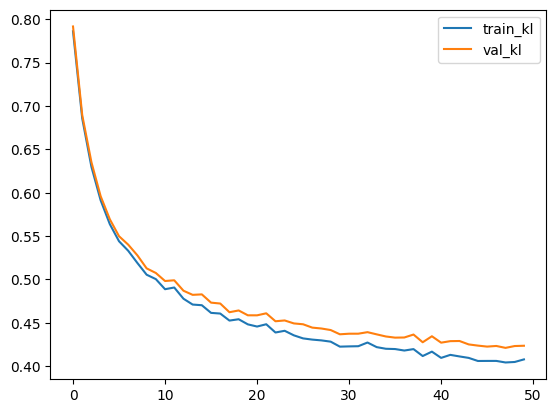

In [89]:
pd.DataFrame(full_history)[['train_kl', 'val_kl']].plot()

In [ ]:
pred = predict(full_trained_model, test)

(array([[1.3967929e-06, 7.3343827e-03, 7.1698409e-01, ..., 3.9176510e-05,
         2.8553956e-08, 4.0699440e-04],
        [1.3454816e-06, 9.2582488e-03, 6.7495507e-01, ..., 4.3650285e-05,
         1.3912876e-08, 3.5831617e-04],
        [4.2980500e-06, 3.7984863e-02, 2.7837229e-01, ..., 9.2719893e-05,
         4.9724107e-08, 1.4416251e-03],
        ...,
        [5.4330290e-03, 2.1671992e-02, 3.6507507e-05, ..., 1.3815064e-03,
         3.5948347e-08, 6.7476323e-03],
        [1.9826428e-03, 1.0894615e-02, 3.4083499e-05, ..., 5.5248750e-04,
         1.8879803e-08, 4.5671659e-03],
        [9.7005209e-03, 2.1062156e-02, 7.0302508e-06, ..., 4.7276064e-04,
         4.0647905e-08, 7.7125803e-03]], shape=(235935, 15), dtype=float32),
 array([[0.        , 0.        , 0.4871795 , ..., 0.        , 0.        ,
         0.        ],
        [0.        , 0.        , 0.84566146, ..., 0.        , 0.        ,
         0.        ],
        [0.        , 0.        , 0.        , ..., 0.        , 0.        ,


In [111]:
df.groupby('year')['ID'].nunique()

year
1992.0    26215
1993.0    26215
1994.0    26215
1995.0    26215
1996.0    26215
1997.0    26215
1998.0    26215
1999.0    26215
2000.0    26215
2001.0    26215
2002.0    26215
2003.0    26215
2004.0    26215
2005.0    26215
2006.0    26215
2007.0    26215
2008.0    26215
2009.0    26215
2010.0    26215
2011.0    26215
2012.0    26215
2013.0    26215
2014.0    26215
2015.0    26215
2016.0    26215
2017.0    26215
2018.0    26215
2019.0    26215
2020.0    26215
2021.0    26215
2022.0    26215
Name: ID, dtype: int64

# Visualise

### Visualise predictions

In [139]:

pred_df = pd.concat([
                backbone,
                pd.DataFrame(pred[0][:26215], columns=target_cols),  
            ], axis=1)

true_df = pd.concat([
                backbone,
                pd.DataFrame(pred[1][:26215], columns=target_cols),
            ], axis=1)

pred_img = to_img(pred_df, target_cols)
true_img = to_img(true_df, target_cols)

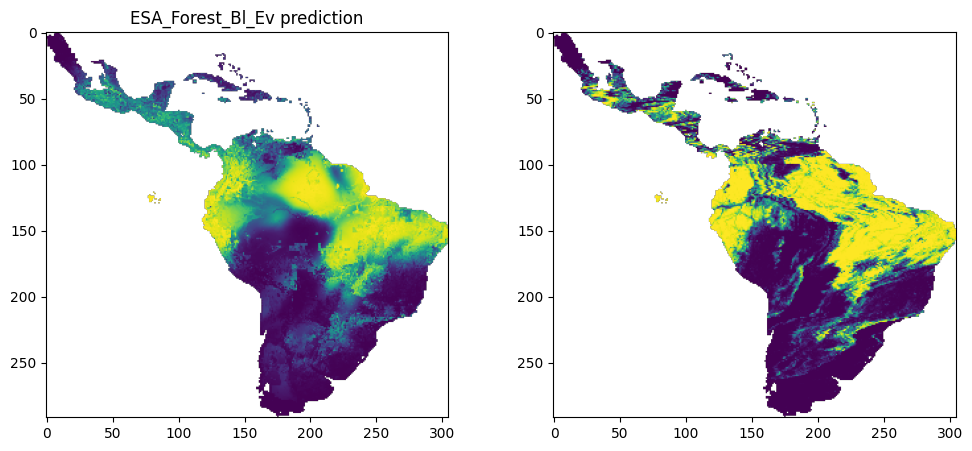

In [148]:
CHANNEL_IDX = 3
fig = plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
show_raster(pred_img[:, :, CHANNEL_IDX], fig=fig)
plt.title(target_cols[CHANNEL_IDX] + ' prediction')
plt.subplot(1, 2, 2)
show_raster(true_img[:, :, CHANNEL_IDX], fig=fig)

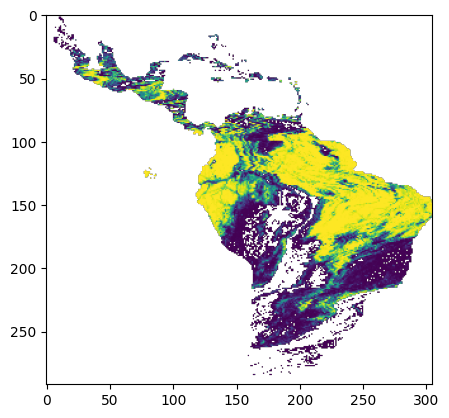

In [155]:
show_raster(to_img(df[df['year'] == 1992], target_cols[3]))

In [161]:
esa['ID'].nunique(), luh['ID'].nunique()

(26215, 26326)

In [157]:
W, H

(305, 292)